In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df["Churn"].value_counts(dropna=False)


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [4]:
df.isnull().sum().sort_values(ascending=False)


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
print("Duplicate rows: ", df.duplicated().sum())
print("Duplicated Customer IDs: ", df["customerID"].duplicated().sum())


Duplicate rows:  0
Duplicated Customer IDs:  0


In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [9]:
print(df["TotalCharges"].head(10).tolist())
      
print("Data type:", df["TotalCharges"].dtype)


['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']
Data type: str


In [10]:
print(df["Churn"].value_counts(dropna=False))
print("\nUnique churn values: ")
print(df["Churn"].unique())

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Unique churn values: 
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [14]:
blank_total_charges = df["TotalCharges"].str.strip().eq("")

print("Blank TotalCharges values:", blank_total_charges.sum())

Blank TotalCharges values: 11


In [15]:
df.loc[
    blank_total_charges,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [22]:
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].str.strip(),
    errors="coerce"
)

In [23]:
print("Original data type:", df["TotalCharges"].dtype)
print("Cleaned data type:", df_clean["TotalCharges"].dtype)

print(
    "Missing TotalCharges after conversion:",
    df_clean["TotalCharges"].isna().sum()
)

print("Original row count:", len(df))
print("Cleaned row count:", len(df_clean))

Original data type: str
Cleaned data type: float64
Missing TotalCharges after conversion: 11
Original row count: 7043
Cleaned row count: 7043


In [24]:
df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [25]:
categorical_columns = df_clean.select_dtypes(
    include=["str", "object", "category"]
).columns
for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))



customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

In [26]:
print("Negative tenure values:", (df_clean["tenure"] < 0).sum())
print("Zero-tenure customers:", (df_clean["tenure"] == 0).sum())
print("Tenure missing values:", df_clean["tenure"].isna().sum())

Negative tenure values: 0
Zero-tenure customers: 11
Tenure missing values: 0


In [27]:
from pathlib import Path

output_path = Path("../data/processed/telco_churn_cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Rows saved:", len(df_clean))

Cleaned dataset saved to: ..\data\processed\telco_churn_cleaned.csv
Rows saved: 7043


In [28]:
df_check = pd.read_csv(output_path)

print("Saved dataset shape:", df_check.shape)
print("TotalCharges data type:", df_check["TotalCharges"].dtype)
print("Missing TotalCharges:", df_check["TotalCharges"].isna().sum())

Saved dataset shape: (7043, 21)
TotalCharges data type: float64
Missing TotalCharges: 11


In [29]:
total_customers = len(df_clean)

churned_customers = (df_clean["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total customers:", total_customers)
print("Customers churned:", churned_customers)
print(f"Overall churn rate: {churn_rate:.2f}%")

Total customers: 7043
Customers churned: 1869
Overall churn rate: 26.54%


In [30]:
churn_counts = df_clean["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [31]:
churn_percentages = (
    df_clean["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentages.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


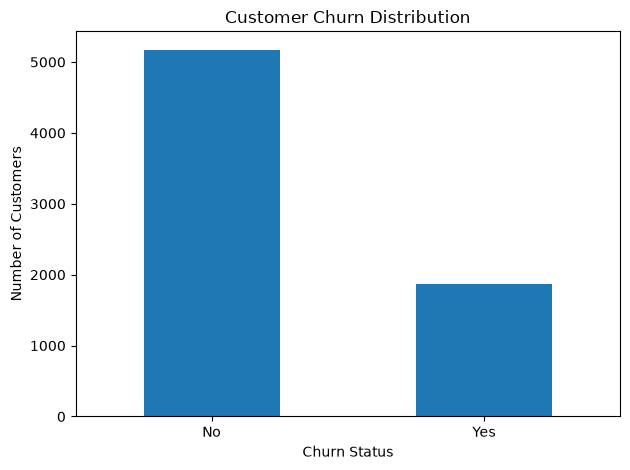

In [32]:
import matplotlib.pyplot as plt

churn_counts.plot(
    kind="bar",
    title="Customer Churn Distribution",
    xlabel="Churn Status",
    ylabel="Number of Customers"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [34]:
contract_churn_rate = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


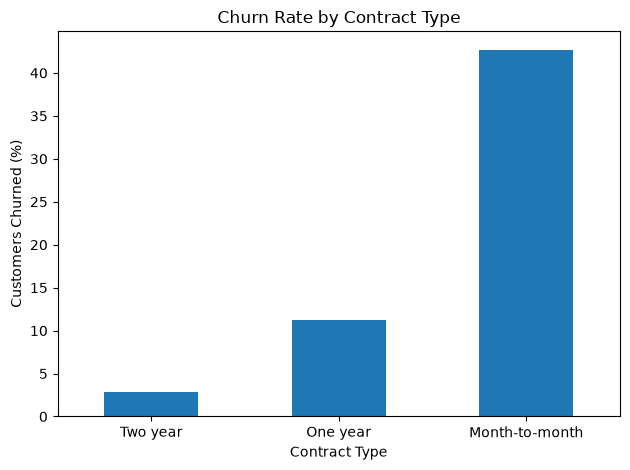

In [35]:
contract_churn_rate["Yes"].sort_values().plot(
    kind="bar",
    title="Churn Rate by Contract Type",
    xlabel="Contract Type",
    ylabel="Customers Churned (%)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, float("inf")],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61+ months"
    ]
)

print(df_clean["TenureGroup"].value_counts().sort_index())

TenureGroup
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-60 months     832
61+ months      1407
Name: count, dtype: int64


In [37]:
tenure_churn_rate = pd.crosstab(
    df_clean["TenureGroup"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(tenure_churn_rate.round(2))

Churn            No    Yes
TenureGroup               
0-12 months   52.56  47.44
13-24 months  71.29  28.71
25-48 months  79.61  20.39
49-60 months  85.58  14.42
61+ months    93.39   6.61


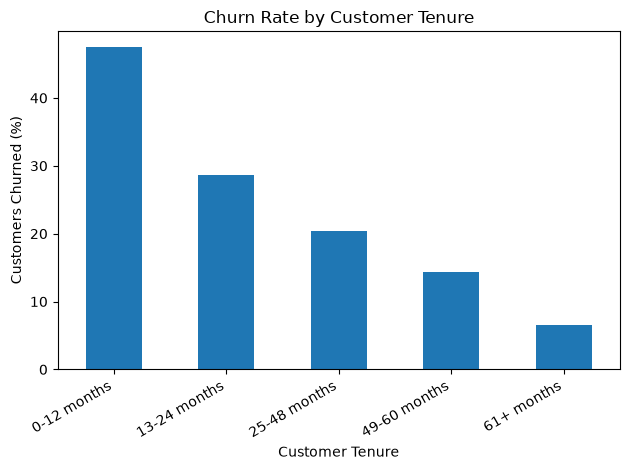

In [38]:
tenure_churn_rate["Yes"].plot(
    kind="bar",
    title="Churn Rate by Customer Tenure",
    xlabel="Customer Tenure",
    ylabel="Customers Churned (%)"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [39]:
payment_churn_rate = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(payment_churn_rate.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


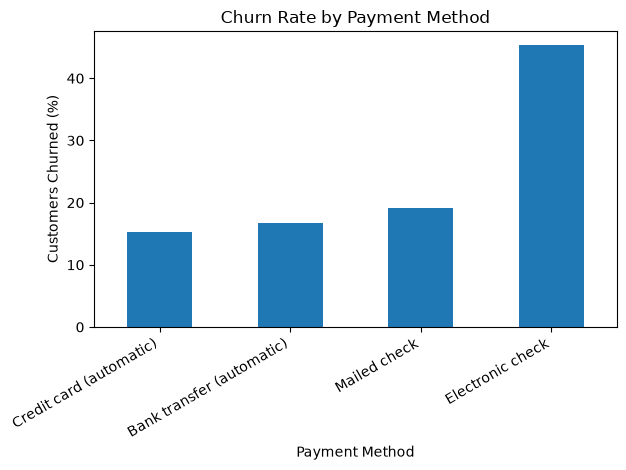

In [40]:
payment_churn_rate["Yes"].sort_values().plot(
    kind="bar",
    title="Churn Rate by Payment Method",
    xlabel="Payment Method",
    ylabel="Customers Churned (%)"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [41]:
monthly_charges_summary = df_clean.groupby("Churn")[
    "MonthlyCharges"
].agg(["count", "mean", "median"])

print(monthly_charges_summary.round(2))

       count   mean  median
Churn                      
No      5174  61.27   64.43
Yes     1869  74.44   79.65
